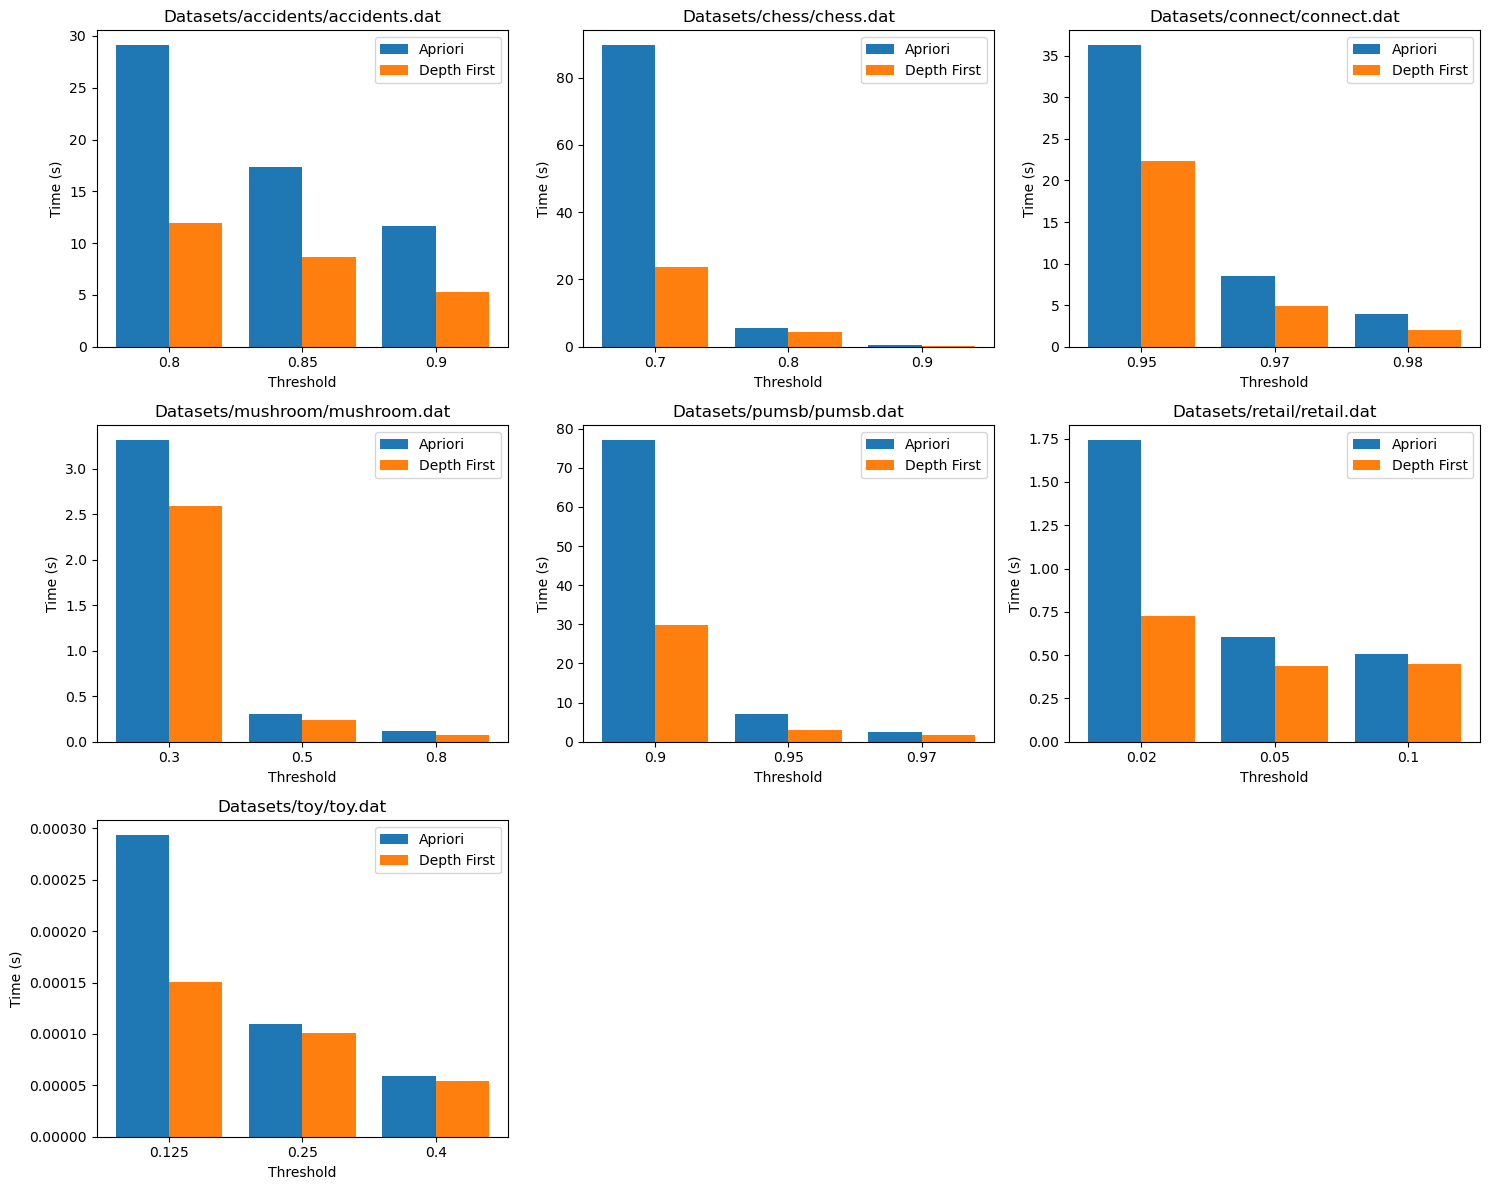

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Charger les données
df = pd.read_csv('execution_times.csv')

# Grouper par test
grouped = list(df.groupby('Test'))
num_tests = len(grouped)

# Créer la figure avec subplots
fig, axes = plt.subplots(3, 3, figsize=(15, 12))  # 3 lignes, 3 colonnes
axes = axes.flatten()  # Transformer en liste pour un accès facile

# Boucle sur chaque test pour remplir les subplots
for i, (name, group) in enumerate(grouped):
    x = np.arange(len(group))  # Positions des barres sur l'axe x
    width = 0.4  # Largeur des barres

    axes[i].bar(x - width/2, group['Apriori Time (s)'], width, label='Apriori')
    axes[i].bar(x + width/2, group['Alternative Miner Time (s)'], width, label='Depth First')

    # Ajouter les labels et le titre
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(group['Threshold'])
    axes[i].set_xlabel('Threshold')
    axes[i].set_ylabel('Time (s)')
    axes[i].set_title(name)
    axes[i].legend()

# Supprimer les subplots vides (si on a moins de 9 tests)
for j in range(num_tests, 9):
    fig.delaxes(axes[j])

# Ajuster la mise en page
plt.tight_layout()
plt.show()
